In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Paths
DATA_DIR = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Show all columns when printing
pd.set_option("display.max_columns", 50)

In [4]:
train = pd.read_csv(DATA_DIR / "train.csv")
demo = pd.read_csv(DATA_DIR / "train_demographics.csv")

print(train.shape)
print(demo.shape)

train.head()

(574945, 341)
(81, 8)


,row_id,sequence_type,sequence_id,sequence_counter,subject,orientation,behavior,phase,gesture,acc_x,acc_y,acc_z,rot_w,rot_x,rot_y,rot_z,thm_1,thm_2,thm_3,thm_4,thm_5,tof_1_v0,tof_1_v1,tof_1_v2,tof_1_v3,...,tof_5_v39,tof_5_v40,tof_5_v41,tof_5_v42,tof_5_v43,tof_5_v44,tof_5_v45,tof_5_v46,tof_5_v47,tof_5_v48,tof_5_v49,tof_5_v50,tof_5_v51,tof_5_v52,tof_5_v53,tof_5_v54,tof_5_v55,tof_5_v56,tof_5_v57,tof_5_v58,tof_5_v59,tof_5_v60,tof_5_v61,tof_5_v62,tof_5_v63
0,SEQ_000007_000000,Target,SEQ_000007,0,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.683594,6.214844,3.355469,0.134399,-0.355164,-0.447327,-0.809753,28.943842,31.822186,29.553024,28.592863,28.310535,131.0,134.0,132.0,135.0,...,-1.0,113.0,124.0,122.0,131.0,-1.0,-1.0,-1.0,-1.0,120.0,127.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1,SEQ_000007_000001,Target,SEQ_000007,1,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.949219,6.214844,3.125000,0.143494,-0.340271,-0.428650,-0.824524,29.340816,31.874645,29.791740,28.663383,28.406172,130.0,138.0,131.0,135.0,...,-1.0,116.0,122.0,123.0,126.0,-1.0,-1.0,-1.0,-1.0,122.0,129.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
2,SEQ_000007_000002,Target,SEQ_000007,2,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,5.722656,5.410156,5.421875,0.219055,-0.274231,-0.356934,-0.865662,30.339359,30.935045,30.090014,28.796087,28.529778,137.0,136.0,147.0,109.0,...,-1.0,133.0,142.0,131.0,130.0,132.0,136.0,-1.0,-1.0,112.0,121.0,123.0,125.0,-1.0,-1.0,-1.0,-1.0,112.0,119.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
3,SEQ_000007_000003,Target,SEQ_000007,3,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.601562,3.531250,6.457031,0.297546,-0.264160,-0.238159,-0.885986,30.543730,27.044001,29.310717,29.018711,27.402010,143.0,147.0,170.0,127.0,...,-1.0,141.0,136.0,120.0,122.0,132.0,-1.0,-1.0,-1.0,107.0,112.0,115.0,140.0,-1.0,-1.0,-1.0,-1.0,101.0,111.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
4,SEQ_000007_000004,Target,SEQ_000007,4,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,5.566406,0.277344,9.632812,0.333557,-0.218628,-0.063538,-0.914856,29.317265,25.270855,26.808746,29.408604,27.357603,178.0,191.0,183.0,157.0,...,-1.0,169.0,171.0,145.0,140.0,-1.0,-1.0,-1.0,-1.0,132.0,125.0,131.0,-1.0,-1.0,-1.0,-1.0,-1.0,101.0,109.0,125.0,-1.0,-1.0,-1.0,-1.0,-1.0


In [5]:
# Group columns by type
cols = train.columns.tolist()
imu_cols = [c for c in cols if c.startswith(("acc_", "rot_"))]
thm_cols = [c for c in cols if c.startswith("thm_")]
tof_cols = [c for c in cols if c.startswith("tof_")]
other_cols = [c for c in cols if c not in imu_cols + thm_cols + tof_cols]

print("IMU:", len(imu_cols), imu_cols)
print("THM:", len(thm_cols), thm_cols)
print("TOF:", len(tof_cols))
print("Other:", other_cols)

IMU: 7 ['acc_x', 'acc_y', 'acc_z', 'rot_w', 'rot_x', 'rot_y', 'rot_z']
THM: 5 ['thm_1', 'thm_2', 'thm_3', 'thm_4', 'thm_5']
TOF: 320
Other: ['row_id', 'sequence_type', 'sequence_id', 'sequence_counter', 'subject', 'orientation', 'behavior', 'phase', 'gesture']


In [6]:
print("Rows:", len(train))
print("Sequences:", train["sequence_id"].nunique())
print("Subjects:", train["subject"].nunique())
print("Avg sequences per subject:",
      train["sequence_id"].nunique() / train["subject"].nunique())

Rows: 574945
Sequences: 8151
Subjects: 81
Avg sequences per subject: 100.62962962962963


In [7]:
# One row per sequence
seq = (
    train.groupby("sequence_id")
    .agg(
        subject=("subject", "first"),
        gesture=("gesture", "first"),
        sequence_type=("sequence_type", "first"),
        orientation=("orientation", "first"),
        length=("sequence_counter", "size"),
    )
    .reset_index()
)

seq = seq.merge(demo, on="subject", how="left")
seq.head()

,sequence_id,subject,gesture,sequence_type,orientation,length,adult_child,age,sex,handedness,height_cm,shoulder_to_wrist_cm,elbow_to_wrist_cm
0,SEQ_000007,SUBJ_059520,Cheek - pinch skin,Target,Seated Lean Non Dom - FACE DOWN,57,0,12,1,1,163.0,52,24.0
1,SEQ_000008,SUBJ_020948,Forehead - pull hairline,Target,Seated Lean Non Dom - FACE DOWN,68,1,24,1,1,173.0,49,26.0
2,SEQ_000013,SUBJ_040282,Cheek - pinch skin,Target,Lie on Side - Non Dominant,53,0,12,1,1,157.0,44,26.0
3,SEQ_000016,SUBJ_052342,Write name on leg,Non-Target,Seated Lean Non Dom - FACE DOWN,61,0,13,0,1,171.0,54,26.0
4,SEQ_000018,SUBJ_032165,Forehead - pull hairline,Target,Seated Lean Non Dom - FACE DOWN,54,0,13,0,1,165.0,52,23.0


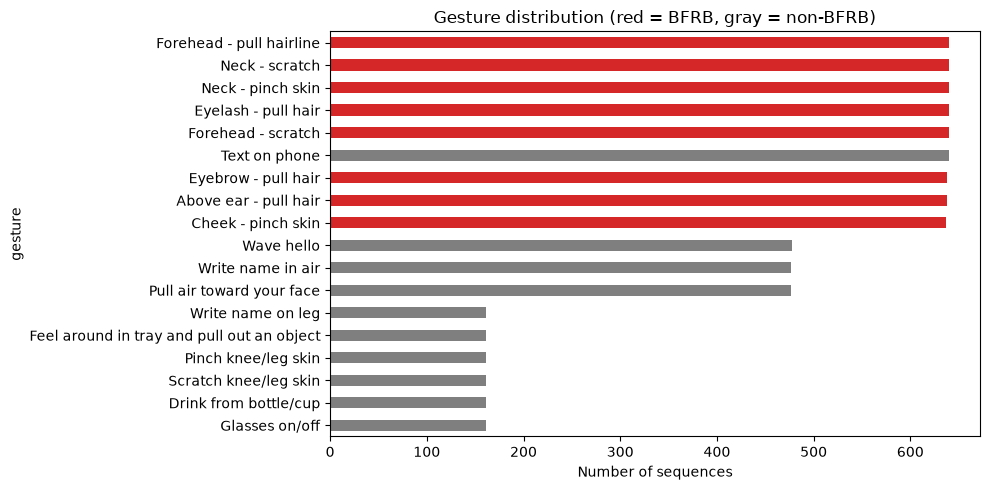

sequence_type
Target        0.627285
Non-Target    0.372715
Name: proportion, dtype: float64


In [8]:
counts = seq["gesture"].value_counts()
colors = [
    "tab:red" if seq.loc[seq.gesture == g, "sequence_type"].iloc[0] == "Target"
    else "tab:gray"
    for g in counts.index
]

fig, ax = plt.subplots(figsize=(10, 5))
counts.plot.barh(ax=ax, color=colors)
ax.invert_yaxis()
ax.set_xlabel("Number of sequences")
ax.set_title("Gesture distribution (red = BFRB, gray = non-BFRB)")
plt.tight_layout()
plt.savefig(FIG_DIR / "gesture_distribution.png", dpi=150)
plt.show()

print(seq["sequence_type"].value_counts(normalize=True))

In [9]:
pivot = pd.crosstab(seq["subject"], seq["gesture"])
print(pivot.describe().T[["min", "max", "mean"]])

                                            min  max      mean
gesture                                                       
Above ear - pull hair                       4.0  8.0  7.876543
Cheek - pinch skin                          4.0  8.0  7.864198
Drink from bottle/cup                       1.0  2.0  1.987654
Eyebrow - pull hair                         4.0  8.0  7.876543
Eyelash - pull hair                         4.0  8.0  7.901235
Feel around in tray and pull out an object  1.0  2.0  1.987654
Forehead - pull hairline                    4.0  8.0  7.901235
Forehead - scratch                          4.0  8.0  7.901235
Glasses on/off                              1.0  2.0  1.987654
Neck - pinch skin                           4.0  8.0  7.901235
Neck - scratch                              4.0  8.0  7.901235
Pinch knee/leg skin                         1.0  2.0  1.987654
Pull air toward your face                   2.0  6.0  5.888889
Scratch knee/leg skin                       1.0  2.0  1

In [10]:
# Find subjects with fewer sequences than usual
seq_per_subject = seq.groupby("subject").size()
print(seq_per_subject.value_counts())
print(seq_per_subject[seq_per_subject < seq_per_subject.max()])

102    76
101     1
97      1
51      1
96      1
54      1
Name: count, dtype: int64
subject
SUBJ_011323    101
SUBJ_016552     97
SUBJ_036405     51
SUBJ_038023     96
SUBJ_053217     54
dtype: int64


## Tổng kết: cấu trúc dữ liệu và phân bố nhãn
- `train.csv` có 574.945 dòng × 341 cột. Mỗi dòng là một thời điểm đo; các dòng cùng `sequence_id` tạo thành một chuỗi. Có 8.151 chuỗi từ 81 người. **Dự đoán theo chuỗi.**
- Cảm biến: IMU 7 cột, nhiệt 5 cột, ToF 320 cột (5 cảm biến × 8×8 pixel). Nhân khẩu học nằm ở file riêng, ghép theo `subject`.
- 18 cử chỉ: 8 BFRB (~63% số chuỗi) và 10 non-BFRB. Số chuỗi mỗi cử chỉ chia 3 mức: ~640, ~480, ~160.
- Mỗi người làm theo kịch bản cố định 102 chuỗi. 76/81 người có đủ; 2 người chỉ có khoảng một nửa (SUBJ_036405, SUBJ_053217).
- Một số non-BFRB có động tác giống BFRB nhưng ở vị trí khác (ví dụ *Neck - scratch* và *Scratch knee/leg skin*).

count    8151.000000
mean       70.536744
std        35.389879
min        29.000000
50%        59.000000
90%       103.000000
95%       127.000000
99%       210.000000
max       700.000000
Name: length, dtype: float64


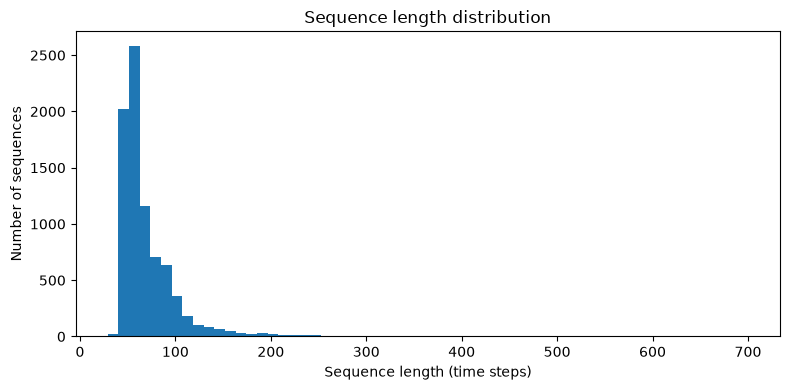

In [11]:
print(seq["length"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(seq["length"], bins=60)
ax.set_xlabel("Sequence length (time steps)")
ax.set_ylabel("Number of sequences")
ax.set_title("Sequence length distribution")
plt.tight_layout()
plt.savefig(FIG_DIR / "sequence_length.png", dpi=150)
plt.show()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21020\1922592569.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([seq.loc[seq.gesture == g, "length"] for g in order],


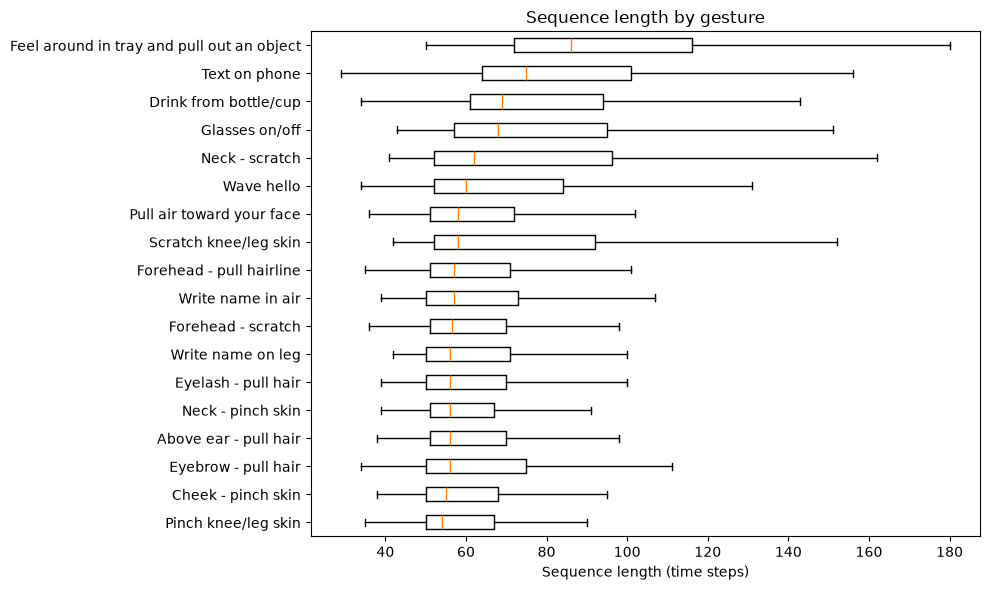

In [12]:
order = seq.groupby("gesture")["length"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([seq.loc[seq.gesture == g, "length"] for g in order],
           vert=False, showfliers=False)
ax.set_yticklabels(order)
ax.set_xlabel("Sequence length (time steps)")
ax.set_title("Sequence length by gesture")
plt.tight_layout()
plt.savefig(FIG_DIR / "length_by_gesture.png", dpi=150)
plt.show()

## Tổng kết: độ dài chuỗi
- Độ dài lệch phải: trung vị 59, 95% ≤ 127, dài nhất 700 bước.
- BFRB có độ dài khá đều (trung vị ~55–62); vài non-BFRB phức tạp dài hơn. Độ dài chỉ là tín hiệu phụ.

In [21]:
# 4a. Missing rate of each sensor group (share of NaN values)
# Compute column by column to avoid copying the large ToF table
def missing_rate(cols):
    return np.mean([train[c].isna().mean() for c in cols])

for name, group in [("IMU", imu_cols), ("THM", thm_cols), ("TOF", tof_cols)]:
    print(f"{name}: {missing_rate(group):.2%}")

IMU: 0.37%
THM: 2.11%


TOF: 1.91%


In [22]:
# 4b. Row-level missing flag for each sensor
tof_sensor_cols = {f"tof_{i}": [c for c in tof_cols if c.startswith(f"tof_{i}_")]
                   for i in range(1, 6)}

miss = pd.DataFrame({"sequence_id": train["sequence_id"]})
miss["IMU"] = train[imu_cols].isna().any(axis=1)
for c in thm_cols:
    miss[c] = train[c].isna()

# A ToF sensor counts as missing at a row when all 64 pixels are NaN
partial = 0
for name, group in tof_sensor_cols.items():
    n_nan = train[group].isna().sum(axis=1)
    miss[name] = n_nan == 64
    partial += ((n_nan > 0) & (n_nan < 64)).sum()
print("Rows where a ToF sensor is only partly NaN:", partial)

miss["THM (whole group)"] = miss[thm_cols].all(axis=1)
miss["TOF (whole group)"] = miss[list(tof_sensor_cols)].all(axis=1)

# Share of missing rows in each sequence
miss_frac = miss.groupby("sequence_id").mean()

def miss_type(frac):
    if frac == 0:
        return "complete"
    if frac == 1:
        return "whole sequence"
    return "some rows"

miss_summary = miss_frac.apply(lambda col: col.map(miss_type).value_counts())
miss_summary.fillna(0).astype(int).T

Rows where a ToF sensor is only partly NaN: 0


,complete,some rows,whole sequence
IMU,8101,0,50
thm_1,8047,0,104
thm_2,8034,1,116
thm_3,8051,0,100
thm_4,8055,0,96
thm_5,7668,1,482
tof_1,8055,0,96
tof_2,8055,0,96
tof_3,8055,0,96
tof_4,8055,0,96


In [23]:
# 4c. Sequences that lose all THM and all ToF data
lost_ids = miss_frac.index[(miss_frac["THM (whole group)"] == 1)
                           & (miss_frac["TOF (whole group)"] == 1)]
lost = seq[seq["sequence_id"].isin(lost_ids)]
print("Sequences without THM and ToF:", len(lost))

subj_table = pd.DataFrame({
    "lost": lost["subject"].value_counts(),
    "total": seq["subject"].value_counts(),
}).dropna().astype(int)
subj_table

Sequences without THM and ToF: 96


,lost,total
subject,,
SUBJ_011323,96,101


In [24]:
# 4d. Do the most often broken sensors (thm_5, tof_5) fail in the same sequences?
# Exclude the sequences that lost all THM and ToF (they are broken everywhere)
broken = miss_frac.drop(index=lost_ids) > 0
print(broken[thm_cols + list(tof_sensor_cols)].sum())

pd.crosstab(broken["thm_5"], broken["tof_5"])

thm_1      8
thm_2     21
thm_3      4
thm_4      0
thm_5    387
tof_1      0
tof_2      0
tof_3      0
tof_4      0
tof_5    339
dtype: int64


tof_5,False,True
thm_5,,
False,7668,0
True,48,339


In [25]:
# Which subjects have broken thm_5 / tof_5 sequences?
broken_5 = seq[seq["sequence_id"].isin(broken.index[broken["thm_5"] | broken["tof_5"]])]
print("Subjects:", broken_5["subject"].nunique())
broken_5["subject"].value_counts()

Subjects: 6


subject
SUBJ_044680    102
SUBJ_016552     97
SUBJ_036450     92
SUBJ_039498     48
SUBJ_036405     39
SUBJ_053217      9
Name: count, dtype: int64

In [28]:
# 4e. Missing values in IMU columns
rot_cols = ["rot_w", "rot_x", "rot_y", "rot_z"]
print(train[imu_cols].isna().sum())

# Are the 4 quaternion components always missing together?
n_rot_nan = train[rot_cols].isna().sum(axis=1)
print("Rows with only some rot_* NaN:", ((n_rot_nan > 0) & (n_rot_nan < 4)).sum())

# Missing pattern per sequence (acc_* has no NaN, so the IMU flag is the rot_* flag)
print(miss_frac["IMU"].map(miss_type).value_counts())
rot_lost = seq[seq["sequence_id"].isin(miss_frac.index[miss_frac["IMU"] > 0])]
rot_lost["subject"].value_counts()

acc_x       0
acc_y       0
acc_z       0
rot_w    3692
rot_x    3692
rot_y    3692
rot_z    3692
dtype: int64
Rows with only some rot_* NaN: 0
IMU
complete          8101
whole sequence      50
Name: count, dtype: int64


subject
SUBJ_058967    24
SUBJ_055211    18
SUBJ_053217     8
Name: count, dtype: int64

In [27]:
# 4f. ToF: -1 means "no object detected", NaN means "not recorded"
rows = []
for name, group in tof_sensor_cols.items():
    values = train[group].to_numpy().ravel()
    values = values[~np.isnan(values)]      # keep recorded values only
    measured = values[values != -1]
    rows.append({
        "sensor": name,
        "share_-1": (values == -1).mean(),
        "min": measured.min(),
        "median": np.median(measured),
        "max": measured.max(),
    })
tof_stats = pd.DataFrame(rows)
tof_stats

,sensor,share_-1,min,median,max
0,tof_1,0.583185,0.0,104.0,249.0
1,tof_2,0.625259,0.0,90.0,249.0
2,tof_3,0.597027,0.0,98.0,249.0
3,tof_4,0.518221,0.0,108.0,249.0
4,tof_5,0.607792,0.0,103.0,249.0


## Tổng kết: dữ liệu thiếu
- Tỉ lệ NaN thấp: IMU 0,37%, nhiệt 2,11%, ToF 1,91%.
- Cảm biến đã thiếu thì **mất trọn cả chuỗi**; chỉ có 3 chuỗi thiếu vài dòng.
- 96 chuỗi mất toàn bộ nhiệt và ToF, tất cả của **SUBJ_011323**.
- `thm_5` (387 chuỗi) và `tof_5` (339 chuỗi) hỏng nhiều nhất, thường hỏng cùng nhau và tập trung ở 6 người → lỗi thiết bị theo người.
- `acc_*` không thiếu; `rot_*` mất trọn ở 50 chuỗi (3 người).
- ToF: khoảng 52–63% giá trị là -1 (không thấy vật); giá trị đo được từ 0 đến 249. -1 khác NaN.
- Theo mô tả cuộc thi, nhiều chuỗi trong tập test chỉ có IMU.

In [30]:
# 5a. Body orientation during the sequence
pd.crosstab(seq["orientation"], seq["sequence_type"], margins=True)

sequence_type,Non-Target,Target,All
orientation,,,
Lie on Back,636,1272,1908
Lie on Side - Non Dominant,631,1272,1903
Seated Lean Non Dom - FACE DOWN,644,1284,1928
Seated Straight,1127,1285,2412
All,3038,5113,8151


In [34]:
# Which gestures are done in which orientation?
pd.crosstab(seq["gesture"], seq["orientation"])

orientation,Lie on Back,Lie on Side - Non Dominant,Seated Lean Non Dom - FACE DOWN,Seated Straight
gesture,,,,
Above ear - pull hair,159,159,159,161
Cheek - pinch skin,159,159,161,158
Drink from bottle/cup,0,0,0,161
Eyebrow - pull hair,159,159,159,161
Eyelash - pull hair,159,159,161,161
Feel around in tray and pull out an object,0,0,0,161
Forehead - pull hairline,159,159,161,161
Forehead - scratch,159,159,161,161
Glasses on/off,0,0,0,161


In [31]:
# 5b. Participants (one row per subject)
# adult_child: 1 = adult, 0 = child | sex: 1 = male, 0 = female | handedness: 1 = right, 0 = left
for col in ["adult_child", "sex", "handedness"]:
    print(demo[col].value_counts(), "\n")

print(f"Left-handed: {(demo['handedness'] == 0).mean():.1%}")
demo[["age", "height_cm", "shoulder_to_wrist_cm", "elbow_to_wrist_cm"]].describe()

adult_child
1    42
0    39
Name: count, dtype: int64 

sex
1    50
0    31
Name: count, dtype: int64 

handedness
1    71
0    10
Name: count, dtype: int64 

Left-handed: 12.3%


,age,height_cm,shoulder_to_wrist_cm,elbow_to_wrist_cm
count,81.000000,81.000000,81.000000,81.000000
mean,21.814815,167.993827,51.580247,25.469136
std,10.289693,10.605863,4.888415,3.025254
min,10.000000,135.000000,41.000000,18.000000
25%,13.000000,163.000000,49.000000,24.000000
50%,22.000000,170.000000,52.000000,25.000000
75%,27.000000,174.000000,55.000000,27.000000
max,53.000000,190.500000,71.000000,44.000000


In [32]:
# 5c. Order of behavior phases inside each sequence
b = train[["sequence_id", "sequence_counter", "behavior", "phase"]]
b = b.sort_values(["sequence_id", "sequence_counter"])

# Keep only rows where the behavior changes, then join them into a pattern
changed = b["behavior"] != b.groupby("sequence_id")["behavior"].shift()
pattern = b[changed].groupby("sequence_id")["behavior"].agg(" -> ".join)
pattern.value_counts()

behavior
Moves hand to target location -> Hand at target location -> Performs gesture                4102
Relaxes and moves hand to target location -> Hand at target location -> Performs gesture    4048
Relaxes and moves hand to target location -> Hand at target location                           1
Name: count, dtype: int64

In [36]:
# Is "Performs gesture" always at the end of the sequence?
last = b.groupby("sequence_id")[["behavior", "phase"]].last()
print(last.value_counts(), "\n")
print(last[last["behavior"] != "Performs gesture"], "\n")

# Length of the gesture phase
gesture_len = (b["phase"] == "Gesture").groupby(b["sequence_id"]).sum()
print(gesture_len.describe(percentiles=[0.5, 0.95, 0.99]))

behavior                 phase     
Performs gesture         Gesture       8150
Hand at target location  Transition       1
Name: count, dtype: int64 

                            behavior       phase
sequence_id                                     
SEQ_011975   Hand at target location  Transition 

count    8151.000000
mean       31.384738
std         3.602887
min         0.000000
50%        31.000000
95%        37.000000
99%        44.000000
max        71.000000
Name: phase, dtype: float64


## Tổng kết: ngữ cảnh và nhân khẩu học
- Có 4 tư thế. 8 BFRB và "Text on phone" được làm ở cả 4 tư thế; các non-BFRB khác chỉ làm ở 1–3 tư thế (ví dụ 3 cử chỉ ở chân chỉ làm khi ngồi cúi).
- 81 người: 42 người lớn / 39 trẻ em, 50 nam / 31 nữ, tuổi 10–53. **Chỉ 10 người (12%) thuận tay trái**, nên có rất ít dữ liệu tay trái.
- Mỗi chuỗi đi theo thứ tự: đưa tay tới vị trí → giữ tay tại vị trí → **thực hiện cử chỉ**.
- 8.150/8.151 chuỗi **kết thúc bằng pha thực hiện cử chỉ** (chỉ SEQ_011975 không có pha này).
- Pha cử chỉ ngắn: trung vị 31 bước, dài nhất 71 bước.
- `orientation`, `behavior`, `phase` (cùng `sequence_type`, `gesture`) chỉ có trong train → **không dùng được làm đầu vào** mô hình.

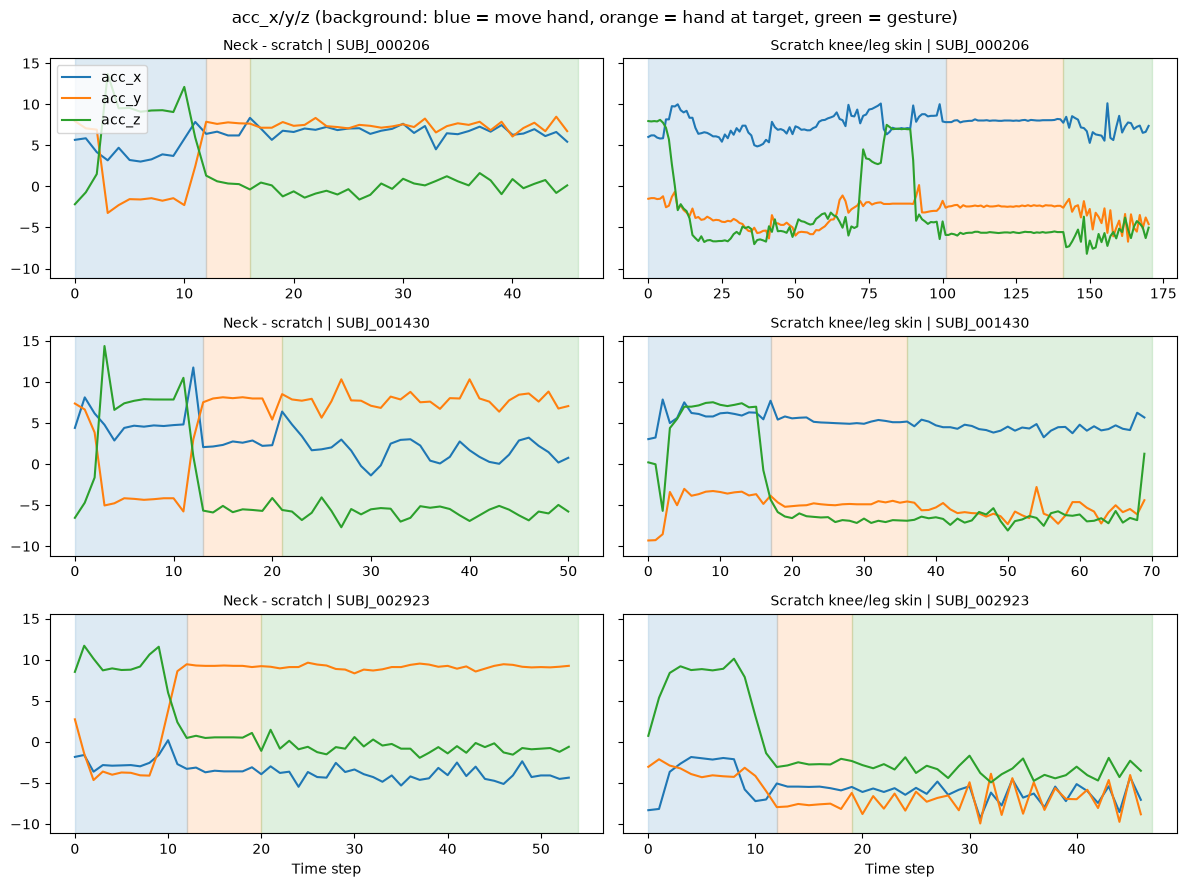

In [38]:
# 6a. Raw accelerometer signal of two easily confused gestures
pair = ["Neck - scratch", "Scratch knee/leg skin"]

# Knee gestures are only done in this orientation, so compare both gestures in it
pick = seq[seq["gesture"].isin(pair)
           & (seq["orientation"] == "Seated Lean Non Dom - FACE DOWN")]
n_gestures = pick.groupby("subject")["gesture"].nunique()
subjects = n_gestures[n_gestures == 2].index[:3]   # subjects having both gestures

phase_colors = {
    "Relaxes and moves hand to target location": "tab:blue",
    "Moves hand to target location": "tab:blue",
    "Hand at target location": "tab:orange",
    "Performs gesture": "tab:green",
}

fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharey=True)
for row, subj in enumerate(subjects):
    for col, g in enumerate(pair):
        sid = pick.loc[(pick["subject"] == subj) & (pick["gesture"] == g), "sequence_id"].iloc[0]
        s = train[train["sequence_id"] == sid].sort_values("sequence_counter")
        ax = axes[row, col]

        # Background color for each behavior phase
        for beh, part in s.groupby("behavior"):
            ax.axvspan(part["sequence_counter"].min(), part["sequence_counter"].max() + 1,
                       color=phase_colors[beh], alpha=0.15)
        for c in ["acc_x", "acc_y", "acc_z"]:
            ax.plot(s["sequence_counter"], s[c], label=c)
        ax.set_title(f"{g} | {subj}", fontsize=10)

axes[0, 0].legend(loc="upper left")
for ax in axes[-1]:
    ax.set_xlabel("Time step")
fig.suptitle("acc_x/y/z (background: blue = move hand, orange = hand at target, green = gesture)")
plt.tight_layout()
plt.savefig(FIG_DIR / "signal_neck_vs_knee.png", dpi=150)
plt.show()

## Nhận xét: tín hiệu thật
- Trong pha cử chỉ (nền xanh lá), cả hai cử chỉ đều là dao động nhỏ, lặp lại → **dạng chuyển động khi gãi gần giống nhau**.
- Khác biệt rõ nhất nằm ở **mức nền của acc** (hướng trọng lực, tức tư thế cổ tay): gãi cổ có `acc_y` dương (~7–9), gãi chân có `acc_y` âm (~-5 đến -8).
- Mức nền thay đổi theo người: SUBJ_002923 (thuận tay trái) có `acc_x` ngược dấu so với hai người còn lại.
- Kết luận: với cặp này, mắt thường **phân biệt được** nhờ tư thế cổ tay chứ không nhờ dạng dao động.
- Pha di chuyển tay có độ dài rất khác nhau (có chuỗi tới 100 bước).

# Tóm tắt phát hiện

**Dữ liệu và nhãn**
- 8.151 chuỗi, 81 người, mỗi người làm theo kịch bản 102 chuỗi. Dự đoán theo chuỗi.
- 18 cử chỉ: 8 BFRB (~63%), 10 non-BFRB. Mất cân bằng nhẹ giữa các lớp (~640 / ~480 / ~160 chuỗi).

**Độ dài và cấu trúc chuỗi**
- Độ dài trung vị 59, 95% ≤ 127 bước.
- Chuỗi luôn kết thúc bằng pha cử chỉ (trung vị 31 bước, tối đa 71).

**Dữ liệu thiếu**
- Cảm biến thiếu thì mất trọn cả chuỗi. Lỗi gắn với từng người: SUBJ_011323 mất toàn bộ nhiệt và ToF, `thm_5`/`tof_5` hỏng ở 6 người, `rot_*` mất ở 50 chuỗi.
- ToF: -1 là "không thấy vật", khác NaN.

**Ngữ cảnh**
- Chỉ 12% người thuận tay trái; tín hiệu tay trái có thể ngược dấu.
- `orientation`, `behavior`, `phase` chỉ có trong train, không dùng được làm đầu vào.
- Cặp gãi cổ / gãi chân có dạng dao động giống nhau, khác nhau ở tư thế cổ tay.

**Quyết định cho nhóm**
1. Chia fold theo `subject` (GroupKFold).
2. Xây mô hình chỉ dùng IMU (cho các chuỗi test chỉ có IMU) và mô hình dùng đủ cảm biến.